## Graph 1: Frequency of AI Usage Across Study Activities

**Graph Type:** Heatmap

**Description:** This heatmap compares how frequently students use AI for different study activities. The rows represent study activities, while the columns represent AI usage frequency levels. Darker blue colors indicate higher percentages of students selecting a response.

**Hypothesis:** We think students are more likely to use AI frequently for asking questions, finding definitions, and reviewing mistakes in their work than for completing coding, STEM homework, or writing-based assignments.

**Takeaway:** Students report using AI very often for asking questions (51.2%), reviewing calculation mistakes (45.3%), and reviewing written mistakes (38.4%). In contrast, fewer students use AI very often for STEM homework (15.1%), coding assignments (15.1%), and writing assignments (12.8%). This suggests that students are more likely to use AI for understanding concepts and reviewing mistakes than for completing assignments directly.

**Data Used:** We used responses from eight survey questions about how frequently students use AI for different study activities. Seven activities contain 86 responses each, while asking for definitions contains 85 responses.

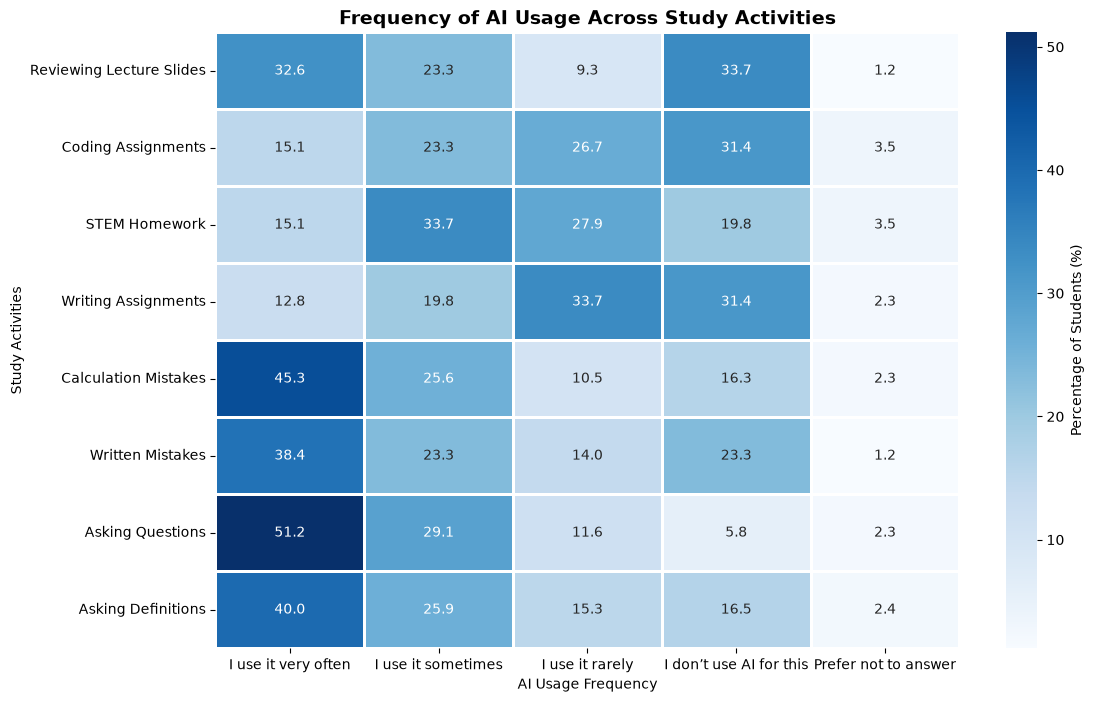

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../../data/uncleaned_data.csv")
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarelly, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_df = survey_df.loc[:, "How often do you use AI for the following:\n [Reviewing Lecture slides]": "How often do you use AI for the following:\n [Asking for definitions]"]
study_df["How often do you use AI for the following:\n [Reviewing Lecture slides]"].value_counts()

# Count responses for each study activity
lecture = study_df.iloc[:, 0].value_counts()
coding = study_df.iloc[:, 1].value_counts()
stem = study_df.iloc[:, 2].value_counts()
writing = study_df.iloc[:, 3].value_counts()
calculation = study_df.iloc[:, 4].value_counts()
written_review = study_df.iloc[:, 5].value_counts()
questions = study_df.iloc[:, 6].value_counts()
definitions = study_df.iloc[:, 7].value_counts()



# Combine response counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture Slides": lecture,
    "Coding Assignments": coding,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T.fillna(0)

# Reorder the response categories
response_order = ["I use it very often", "I use it sometimes", "I use it rarely", "I don’t use AI for this", "Prefer not to answer"]

cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages
percentage_survey = (cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100)

# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()



In [2]:
print("Number of responses per activity:")
print(cross_survey.sum(axis=1))

print("\nHeatmap percentages:")
print(percentage_survey.round(1))

Number of responses per activity:
Reviewing Lecture Slides    86
Coding Assignments          86
STEM Homework               86
Writing Assignments         86
Calculation Mistakes        86
Written Mistakes            86
Asking Questions            86
Asking Definitions          85
dtype: int64

Heatmap percentages:
                          I use it very often  I use it sometimes  \
Reviewing Lecture Slides                 32.6                23.3   
Coding Assignments                       15.1                23.3   
STEM Homework                            15.1                33.7   
Writing Assignments                      12.8                19.8   
Calculation Mistakes                     45.3                25.6   
Written Mistakes                         38.4                23.3   
Asking Questions                         51.2                29.1   
Asking Definitions                       40.0                25.9   

                          I use it rarely  I don’t use AI for

## Hypothesis: Correlation Test

**What we suspect**

We think students who frequently use AI for asking questions and clarifying concepts are also more likely to use AI frequently for reviewing calculation mistakes.

**Our analysis**

We converted the frequency responses into numerical values from 0 to 3, where 0 means "I don't use AI for this" and 3 means "I use it very often." We used Spearman's rank correlation to test the relationship between these two study activities because the responses are ordered categories. We excluded missing responses and students who preferred not to answer.

**Null Hypothesis (H₀):** There is no monotonic correlation between how frequently students use AI for asking questions and reviewing calculation mistakes.

**Alternative Hypothesis (H₁):** There is a monotonic correlation between the two activities.

In [ ]:
from scipy.stats import spearmanr

# Convert frequency responses into numerical values
frequency_scale = {
    "I don’t use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3
}

# Select the two activities from study_df
questions_score = study_df.iloc[:, 6].map(frequency_scale)
calculation_score = study_df.iloc[:, 4].map(frequency_scale)

# Combine responses and remove missing values
correlation_df = pd.DataFrame({
    "Asking Questions": questions_score,
    "Reviewing Calculation Mistakes": calculation_score
}).dropna()

# Perform Spearman correlation test
rho, p_value = spearmanr(
    correlation_df["Asking Questions"],
    correlation_df["Reviewing Calculation Mistakes"]
)

print(f"Sample size: {len(correlation_df)}")
print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")


Sample size: 83
Spearman correlation: 0.585
P-value: 0.0000


**Findings**

- Valid paired responses: 83
- Spearman correlation coefficient: 0.585
- P-value: p < 0.0001
- Significance level: 0.05
- The correlation is positive and statistically significant.

**Conclusion**

Since the p-value is smaller than 0.05, we reject the null hypothesis. The results indicate a statistically significant, moderate positive correlation between students' frequency of using AI for asking questions and reviewing calculation mistakes. This suggests that students who frequently use AI for one activity also tend to use it frequently for the other, but it does not prove causation.